# Hexbug urn model

turn each crossing log into n_L(t), the number of bugs on the left every 0.1 s, and look at all runs together.

Logs live in `data/crossings/N{N}_run{R}.csv` with columns `time,direction` (time from release, all bugs start on the left). 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data/crossings")
DT = 0.1  # time step of the grid (s)

# one fixed color per N, so the same N is always the same color
COLORS = {2: "#2a78d6", 4: "#eb6834", 6: "#1baf7a", 8: "#eda100", 10: "#e87ba4"}

In [ ]:
def read_run(path):
    """Read one crossing log. N and the run number come from the name"""
    N_part, run_part = path.stem.split("_")
    N = int(N_part.removeprefix("N"))
    run = int(run_part.removeprefix("run"))

    log = pd.read_csv(path)
    if not log["time"].is_monotonic_increasing:
        raise ValueError(f"{path.name}: times are out of order")

    # Use the 'end' row if there is one, otherwise stop at the last crossing
    end = log["time"].iloc[-1]
    log = log[log["direction"] != "end"]
    return N, run, log, end


def n_left_on_grid(log, N, end):
    """Number of bugs on the left every DT seconds, from release to the end."""
    times = np.arange(0, end, DT)
    n_left = np.full(len(times), N)

    # each crossing changes the count from its time onward: R = one fewer on the left, L = one more
    for time, direction in zip(log["time"], log["direction"]):
        step = {"R": -1, "L": +1}[direction]
        n_left[times >= time] += step

    if n_left.min() < 0 or n_left.max() > N:
        raise ValueError(f"count leaves the range 0..{N}, a crossing is missing or mistyped")
    return times, n_left

In [3]:
# Load every run
runs = []
for path in sorted(DATA.glob("N*_run*.csv")):
    N, run, log, end = read_run(path)
    times, n_left = n_left_on_grid(log, N, end)
    runs.append({"N": N, "run": run, "crossings": len(log), "end": end, "times": times, "n_left": n_left})

runs.sort(key=lambda r: (r["N"], r["run"]))
pd.DataFrame(runs)[["N", "run", "crossings", "end"]]

,N,run,crossings,end
0,2,9,11,125.33
1,2,12,9,107.15
2,4,10,21,124.29
3,6,11,34,130.06
4,8,7,89,238.50


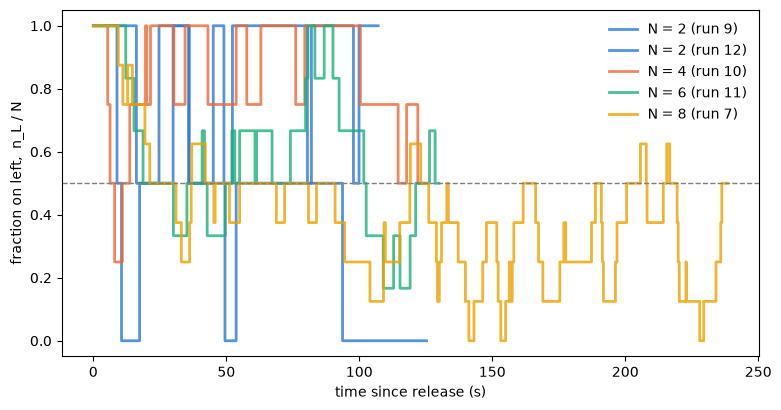

In [4]:
# Fraction of bugs on the left vs time, every run on one plot
fig, ax = plt.subplots(figsize=(9, 4.5))
for r in runs:
    ax.step(r["times"], r["n_left"] / r["N"], where="post", lw=2, alpha=0.8,
            color=COLORS[r["N"]], label=f"N = {r['N']} (run {r['run']})")

ax.axhline(0.5, color="gray", ls="--", lw=1)  # even split
ax.set(xlabel="time since release (s)", ylabel="fraction on left,  n_L / N", ylim=(-0.05, 1.05))
ax.legend(frameon=False)
plt.show()